In [2]:

# Cell 1: Import libraries and inspect a small sample

import pandas as pd
from pathlib import Path

# Path to the original electricity dataset
DATA_PATH = Path("../data/raw/LD2011_2014.txt")

# Check that the dataset exists
print("Dataset exists:", DATA_PATH.exists())

# Read only the first 10 rows and first 6 columns
sample = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    nrows=10,
    usecols=range(6)
)

# Display the dataset structure
print("\nDataset shape (sample):", sample.shape)
print("\nColumn names:")
print(sample.columns.tolist())

print("\nData types:")
print(sample.dtypes)

print("\nFirst 5 rows:")
display(sample.head())


Dataset exists: True

Dataset shape (sample): (10, 6)

Column names:
['Unnamed: 0', 'MT_001', 'MT_002', 'MT_003', 'MT_004', 'MT_005']

Data types:
Unnamed: 0    object
MT_001         int64
MT_002         int64
MT_003         int64
MT_004         int64
MT_005         int64
dtype: object

First 5 rows:


,Unnamed: 0,MT_001,MT_002,MT_003,MT_004,MT_005
0,2011-01-01 00:15:00,0,0,0,0,0
1,2011-01-01 00:30:00,0,0,0,0,0
2,2011-01-01 00:45:00,0,0,0,0,0
3,2011-01-01 01:00:00,0,0,0,0,0
4,2011-01-01 01:15:00,0,0,0,0,0


In [3]:

# Cell 2: Check timestamps and missing values in the sample

# Rename the timestamp column
sample = sample.rename(columns={"Unnamed: 0": "timestamp"})

# Convert timestamp text into datetime values
sample["timestamp"] = pd.to_datetime(sample["timestamp"])

# Display timestamp information
print("Timestamp data type:", sample["timestamp"].dtype)
print("First timestamp:", sample["timestamp"].min())
print("Last timestamp:", sample["timestamp"].max())

# Check missing values in each column
print("\nMissing values per column:")
print(sample.isnull().sum())

# Check whether timestamps are in increasing order
print("\nTimestamps are increasing:",
      sample["timestamp"].is_monotonic_increasing)

# Display the time difference between consecutive rows
print("\nTime difference between rows:")
print(sample["timestamp"].diff())


Timestamp data type: datetime64[ns]
First timestamp: 2011-01-01 00:15:00
Last timestamp: 2011-01-01 02:30:00

Missing values per column:
timestamp    0
MT_001       0
MT_002       0
MT_003       0
MT_004       0
MT_005       0
dtype: int64

Timestamps are increasing: True

Time difference between rows:
0               NaT
1   0 days 00:15:00
2   0 days 00:15:00
3   0 days 00:15:00
4   0 days 00:15:00
5   0 days 00:15:00
6   0 days 00:15:00
7   0 days 00:15:00
8   0 days 00:15:00
9   0 days 00:15:00
Name: timestamp, dtype: timedelta64[ns]


In [4]:

# Cell 3: Descriptive statistics for the sample

# Select only numeric client columns
numeric_columns = sample.select_dtypes(include="number").columns

# Summary statistics
print("Summary statistics:")
display(sample[numeric_columns].describe().T)

# Count zero readings for each client in the sample
print("\nZero readings per client:")
print((sample[numeric_columns] == 0).sum())

# Count distinct values in each client column
print("\nDistinct values per client:")
print(sample[numeric_columns].nunique())


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
MT_001,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_002,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_003,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_004,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_005,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Zero readings per client:
MT_001    10
MT_002    10
MT_003    10
MT_004    10
MT_005    10
dtype: int64

Distinct values per client:
MT_001    1
MT_002    1
MT_003    1
MT_004    1
MT_005    1
dtype: int64


In [5]:

# Cell 4: Inspect readings from a later period

DATA_PATH = "../data/raw/LD2011_2014.txt"

# Skip the header and first 1,000 data rows, then read 10 rows
later_sample = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    skiprows=range(1, 1001),
    nrows=10,
    usecols=range(6)
)

# Rename and convert the timestamp
later_sample = later_sample.rename(
    columns={"Unnamed: 0": "timestamp"}
)
later_sample["timestamp"] = pd.to_datetime(
    later_sample["timestamp"]
)

print("Later sample timestamps:")
print(later_sample["timestamp"])

print("\nClient readings:")
display(later_sample.head())

print("\nSummary statistics:")
display(later_sample.select_dtypes(include="number").describe().T)


Later sample timestamps:
0   2011-01-11 10:15:00
1   2011-01-11 10:30:00
2   2011-01-11 10:45:00
3   2011-01-11 11:00:00
4   2011-01-11 11:15:00
5   2011-01-11 11:30:00
6   2011-01-11 11:45:00
7   2011-01-11 12:00:00
8   2011-01-11 12:15:00
9   2011-01-11 12:30:00
Name: timestamp, dtype: datetime64[ns]

Client readings:


,timestamp,MT_001,MT_002,MT_003,MT_004,MT_005
0,2011-01-11 10:15:00,0,0,0,0,0
1,2011-01-11 10:30:00,0,0,0,0,0
2,2011-01-11 10:45:00,0,0,0,0,0
3,2011-01-11 11:00:00,0,0,0,0,0
4,2011-01-11 11:15:00,0,0,0,0,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
MT_001,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_002,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_003,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_004,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MT_005,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:

# Cell 5: Identify clients with non-zero readings

DATA_PATH = "../data/raw/LD2011_2014.txt"

# Read a small sample from the middle of the dataset
sample_all = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    skiprows=range(1, 70000),
    nrows=100,
)

# Convert all client readings to numeric values
client_data = sample_all.iloc[:, 1:].apply(
    pd.to_numeric, errors="coerce"
)

# Count non-zero readings for every client
nonzero_counts = (client_data != 0).sum().sort_values(
    ascending=False
)

print("Number of clients:", len(client_data.columns))
print("\nClients with the most non-zero readings:")
display(nonzero_counts.head(15))

print("\nClients with no non-zero readings in this sample:",
      (nonzero_counts == 0).sum())


Number of clients: 370

Clients with the most non-zero readings:


MT_369    100
MT_353    100
MT_352    100
MT_351    100
MT_350    100
MT_349    100
MT_346    100
MT_345    100
MT_344    100
MT_343    100
MT_342    100
MT_341    100
MT_340    100
MT_339    100
MT_338    100
dtype: int64


Clients with no non-zero readings in this sample: 39


In [7]:

# Cell 6: Compare client activity in the sample

# Count zero and non-zero readings for each client
activity_summary = pd.DataFrame({
    "nonzero_count": (client_data != 0).sum(),
    "zero_count": (client_data == 0).sum(),
    "mean_demand": client_data.mean(),
    "max_demand": client_data.max()
})

# Calculate percentage of non-zero readings
activity_summary["nonzero_percent"] = (
    activity_summary["nonzero_count"] / len(client_data) * 100
)

# Show the 10 most consistently active clients
display(
    activity_summary
    .sort_values("nonzero_percent", ascending=False)
    .head(10)
)

print("\nClients with at least 90% non-zero readings:",
      (activity_summary["nonzero_percent"] >= 90).sum())


,nonzero_count,zero_count,mean_demand,max_demand,nonzero_percent
MT_369,100,0,643.607038,697.214076,100.0
MT_353,100,0,456.401539,749.198204,100.0
MT_352,100,0,66.376594,137.284321,100.0
MT_351,100,0,1644.800000,3173.333333,100.0
MT_350,100,0,700.995025,1417.910448,100.0
MT_349,100,0,145.558350,318.410463,100.0
MT_346,100,0,293.204868,429.006085,100.0
MT_345,100,0,2165.072464,3164.251208,100.0
MT_344,100,0,165.231750,411.935110,100.0
MT_343,100,0,120.809816,268.098160,100.0



Clients with at least 90% non-zero readings: 329


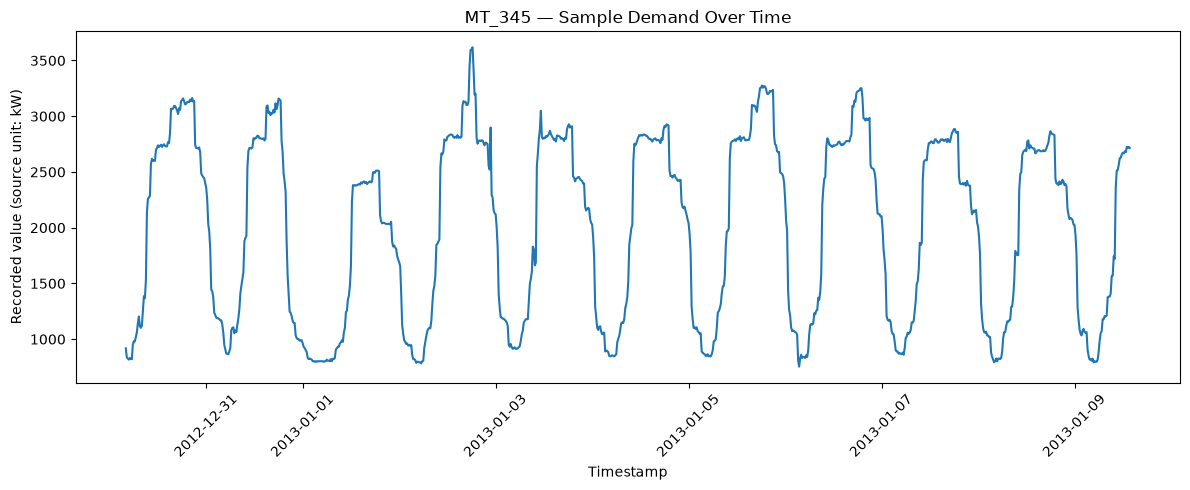

In [10]:

# Cell 7: Plot a candidate client's readings over time
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/LD2011_2014.txt"

# Read a manageable sample of 1,000 consecutive rows
plot_data = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    skiprows=range(1, 70000),
    nrows=1000,
    usecols=[0, 345]
)

plot_data.columns = ["timestamp", "MT_345"]
plot_data["timestamp"] = pd.to_datetime(plot_data["timestamp"])

# Plot the time series
plt.figure(figsize=(12, 5))
plt.plot(plot_data["timestamp"], plot_data["MT_345"])
plt.title("MT_345 — Sample Demand Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Recorded value (source unit: kW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [11]:

# Cell 8: Quantify the plotted time series

print("Number of readings:", len(plot_data))
print("Start:", plot_data["timestamp"].min())
print("End:", plot_data["timestamp"].max())

print("\nSummary statistics:")
print(plot_data["MT_345"].describe())

print("\nMissing readings:", plot_data["MT_345"].isna().sum())
print("Zero readings:", (plot_data["MT_345"] == 0).sum())

print("\nTime interval counts:")
print(plot_data["timestamp"].diff().value_counts().head())


Number of readings: 1000
Start: 2012-12-30 04:00:00
End: 2013-01-09 13:45:00

Summary statistics:
count    1000.000000
mean     2004.560386
std       826.741784
min       753.623188
25%      1106.280193
50%      2193.236715
75%      2772.946860
max      3618.357488
Name: MT_345, dtype: float64

Missing readings: 0
Zero readings: 0

Time interval counts:
timestamp
0 days 00:15:00    999
Name: count, dtype: int64


Hourly readings: 250
Missing hourly values: 0

Hourly summary:


count     250.000000
mean     2004.560386
std       820.683856
min       792.270531
25%      1110.507246
50%      2210.748792
75%      2771.135266
max      3458.937198
Name: MT_345, dtype: float64


Average demand by hour of day:


,average_power_kW
timestamp,
0,1723.550725
1,1144.444444
2,1057.004831
3,929.347826
4,857.487923
5,846.288977
6,990.777339
7,1119.016249
8,1295.234958


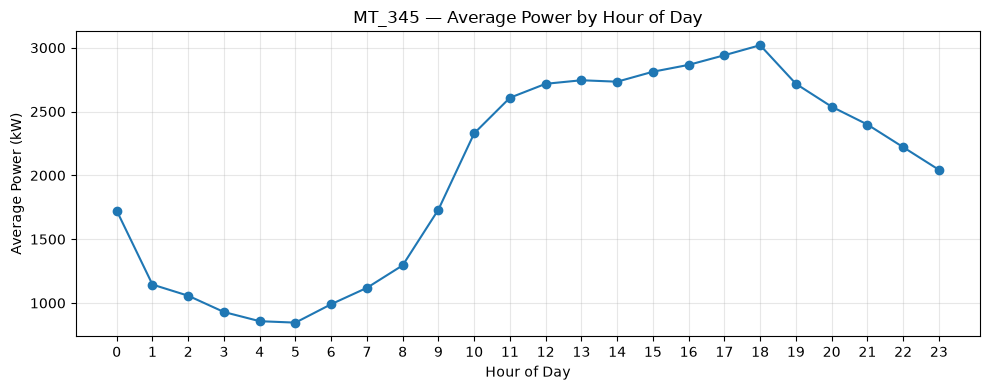

In [12]:

# Cell 9: Examine hourly and daily patterns in MT_345

# Copy the existing sample so earlier cells remain unchanged
daily_data = plot_data[["timestamp", "MT_345"]].copy()

# Set timestamp as the index
daily_data = daily_data.set_index("timestamp")

# Convert 15-minute readings into hourly average power (kW)
hourly_data = daily_data["MT_345"].resample("h").mean()

print("Hourly readings:", len(hourly_data))
print("Missing hourly values:", hourly_data.isna().sum())

print("\nHourly summary:")
display(hourly_data.describe())

# Average demand by hour of the day
hour_of_day = hourly_data.groupby(hourly_data.index.hour).mean()

print("\nAverage demand by hour of day:")
display(hour_of_day.rename("average_power_kW").to_frame())

# Plot average demand by hour
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(hour_of_day.index, hour_of_day.values, marker="o")
plt.title("MT_345 — Average Power by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (kW)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Weekday vs weekend summary:


,mean,median,min,max,count
day_type,,,,,
Weekday,1923.096831,2121.376812,792.270531,3458.937198,182
Weekend,2222.595197,2651.570048,842.995169,3264.492754,68


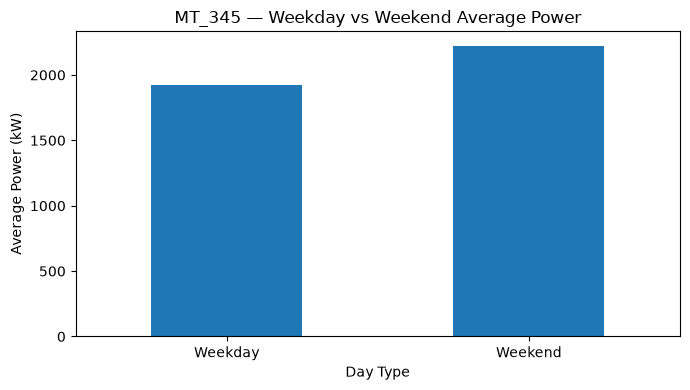

In [13]:

# Cell 10: Compare weekday and weekend power

# Use the existing hourly series
weekday_data = hourly_data.dropna().to_frame(name="power_kW")

# Extract day information
weekday_data["day_of_week"] = weekday_data.index.dayofweek
weekday_data["day_name"] = weekday_data.index.day_name()

# Monday-Friday = weekday; Saturday-Sunday = weekend
weekday_data["day_type"] = weekday_data["day_of_week"].map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Compare average power
comparison = weekday_data.groupby("day_type")["power_kW"].agg(
    ["mean", "median", "min", "max", "count"]
)

print("Weekday vs weekend summary:")
display(comparison)

# Plot the comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
comparison["mean"].plot(kind="bar")
plt.title("MT_345 — Weekday vs Weekend Average Power")
plt.xlabel("Day Type")
plt.ylabel("Average Power (kW)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Average power by day of week:


,day_number,day_name,mean,median,min,max,count
0,0,Monday,1971.945451,2138.888889,873.188406,3077.294686,48
1,1,Tuesday,1766.329509,1966.183575,799.516908,2846.618357,48
2,2,Wednesday,1910.786931,1768.115942,792.270531,3458.937198,38
3,3,Thursday,2051.026570,2323.067633,917.874396,2911.835749,24
4,4,Friday,2030.495169,2339.371981,851.449275,2916.666667,24
5,5,Saturday,2190.217391,2586.352657,851.449275,3264.492754,24
6,6,Sunday,2240.255819,2654.589372,842.995169,3233.091787,44


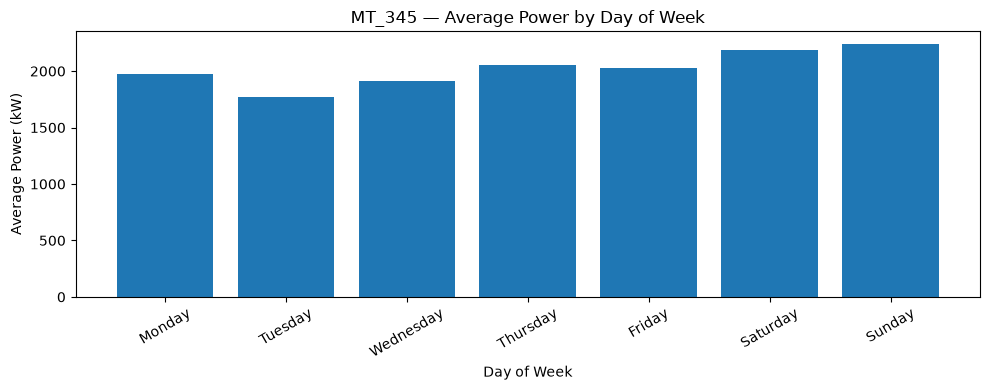

In [14]:

# Cell 11: Average power by day of the week

daily_pattern = hourly_data.dropna().to_frame(name="power_kW")

# Extract weekday name and weekday number
daily_pattern["day_number"] = daily_pattern.index.dayofweek
daily_pattern["day_name"] = daily_pattern.index.day_name()

# Calculate average power for each day
day_summary = (
    daily_pattern.groupby(["day_number", "day_name"])["power_kW"]
    .agg(["mean", "median", "min", "max", "count"])
    .reset_index()
    .sort_values("day_number")
)

print("Average power by day of week:")
display(day_summary)

# Plot mean power by day
plt.figure(figsize=(10, 4))
plt.bar(day_summary["day_name"], day_summary["mean"])
plt.title("MT_345 — Average Power by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Power (kW)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Daily average power:


,average_power_kW
timestamp,
2012-12-30,2353.200483
2012-12-31,1925.372383
2013-01-01,1565.569646
2013-01-02,2116.042673
2013-01-03,2051.026570
2013-01-04,2030.495169
2013-01-05,2190.217391
2013-01-06,2146.135266
2013-01-07,2018.518519


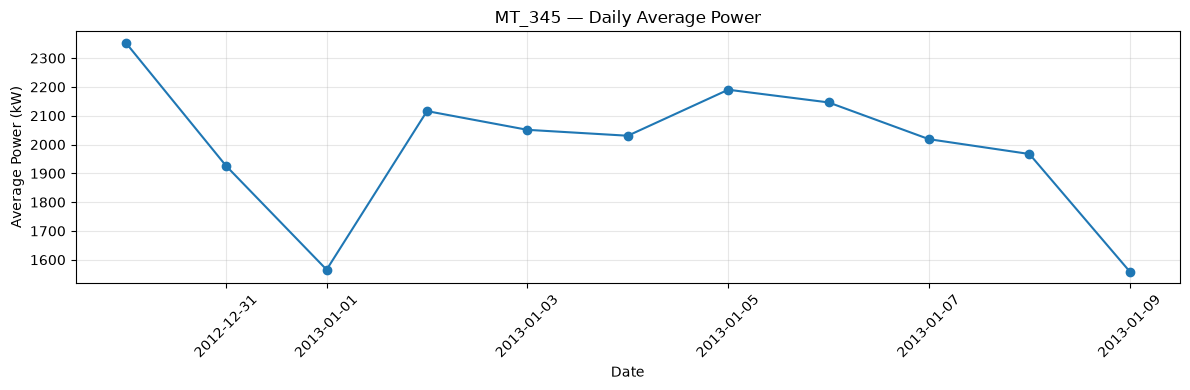

In [15]:

# Cell 12: Average power for each calendar date

daily_means = hourly_data.dropna().resample("D").mean()

print("Daily average power:")
display(daily_means.rename("average_power_kW").to_frame())

# Plot daily average power
plt.figure(figsize=(12, 4))
plt.plot(daily_means.index, daily_means.values, marker="o")
plt.title("MT_345 — Daily Average Power")
plt.xlabel("Date")
plt.ylabel("Average Power (kW)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

# Cell 13: Check hourly coverage for each date

daily_coverage = hourly_data.resample("D").agg(
    hourly_observations="count",
    daily_mean="mean"
)

daily_coverage["full_24_hours"] = (
    daily_coverage["hourly_observations"] == 24
)

print("Daily coverage:")
display(daily_coverage)

print(
    "\nDates with 24 hourly observations:",
    daily_coverage["full_24_hours"].sum()
)

print(
    "Dates with fewer than 24 hourly observations:",
    (daily_coverage["hourly_observations"] < 24).sum()
)


Daily coverage:


,hourly_observations,daily_mean,full_24_hours
timestamp,,,
2012-12-30,20,2353.200483,False
2012-12-31,24,1925.372383,True
2013-01-01,24,1565.569646,True
2013-01-02,24,2116.042673,True
2013-01-03,24,2051.026570,True
2013-01-04,24,2030.495169,True
2013-01-05,24,2190.217391,True
2013-01-06,24,2146.135266,True
2013-01-07,24,2018.518519,True



Dates with 24 hourly observations: 9
Dates with fewer than 24 hourly observations: 2
